## Diagnose why the model is making constant predictions in some cases

The layered model in the refactored code will sometimes predict a constant mean/variance for every input. Why?

#### First: single model

In [1]:
from mmbo.nn import RegBNN, LayeredRegBNN, RegBNNGuide, LayeredRegBNNGuide
from mmbo.examples.demo import paciorek_demo

# Unpack the included data from dictionary
X_train_main = paciorek_demo["X_train_main"]
X_train_mm =   paciorek_demo["X_train_mm"]
X_test =       paciorek_demo["X_test"]
Y_train_main = paciorek_demo["Y_train_main"]
Y_train_mm =   paciorek_demo["Y_train_mm"]
Y_test_main =  paciorek_demo["Y_test_main"]
Y_test_mm =    paciorek_demo["Y_test_mm"]


In [2]:
learning_rate = 0.001

In [3]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single = RegBNN.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256])

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single = RegBNNGuide(model_single)

In [4]:
import pyro
from mmbo.training import do_svi

adam = pyro.optim.Adam({"lr": learning_rate})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi = pyro.infer.SVI(model_single, guide_single, adam, elbo)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single, losses_single = do_svi(svi, params = None, min_iter = 10000, X_train = X_train_main, Y_train = Y_train_main)

2026-09-02 11:05:51 - Start


/home/itaylor/projects/ds4mems/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:279: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


2026-09-02 11:06:27 - Step 1000, Elbo loss: 47953.3 +/- 29506.4 (slope = -50617.319 +/- 434.735 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:06:59 - Step 2000, Elbo loss: 16236.4 +/- 10087.4 (slope = -17286.579 +/- 156.794 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:07:31 - Step 3000, Elbo loss: 5571.7 +/- 3320.6 (slope = -5687.594 +/- 52.856 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:08:05 - Step 4000, Elbo loss: 2093.2 +/- 1077.1 (slope = -1841.070 +/- 18.749 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:08:38 - Step 5000, Elbo loss: 967.8 +/- 349.6 (slope = -594.919 +/- 7.055 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:09:12 - Step 6000, Elbo loss: 596.8 +/- 124.1 (slope = -205.956 +/- 3.889 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:09:48 - Step 7000, Elbo loss: 468.0 +/- 50.2 (slope = -73.652 +/- 2.916 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:10:25 - Step 8000, Elbo loss: 420.4 +/- 28.5 (slope = -26.997 +/- 2.617 loss/k-iter, p-value = 0.000) + 
2026-09-02 1

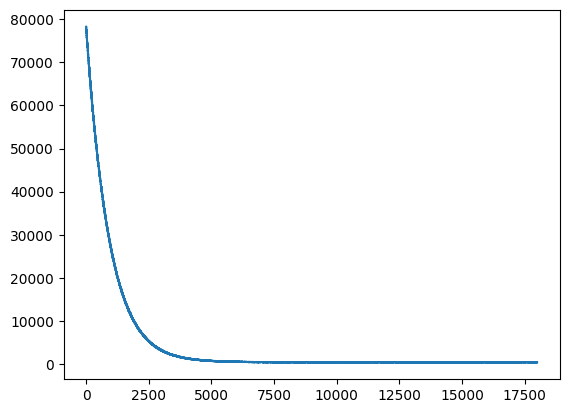

In [5]:
import matplotlib.pyplot as plt

plt.plot(losses_single)

In [6]:
from mmbo.nn import posterior_samples
samples_single = posterior_samples(guide_single, params_single, 1000, X_train = X_train_main, Y_train = Y_train_main)

/home/itaylor/projects/ds4mems/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:279: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


In [7]:
samples_single.keys()

dict_keys(['net.layers.0.0.bW', 'net.layers.0.1.scale', 'net.layers.1.0.bW', 'net.layers.1.1.scale', 'net.precision', 'net.last_bW', 'train/Y_normed_full', 'train/activation_1', 'train/activation_2', 'train/activation_last', 'train/mu', 'train/obs_normed'])

In [8]:
from mmbo.nn import predictor

pred_single = predictor(model_single, samples_single)
Y_test_pred_single = pred_single(X_test)
Y_train_pred_single = pred_single(X_train_main)

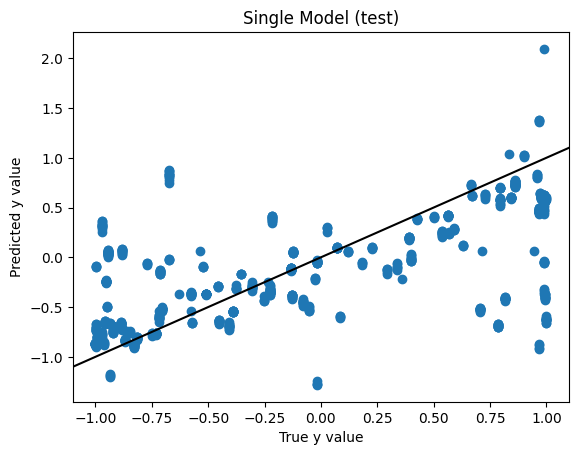

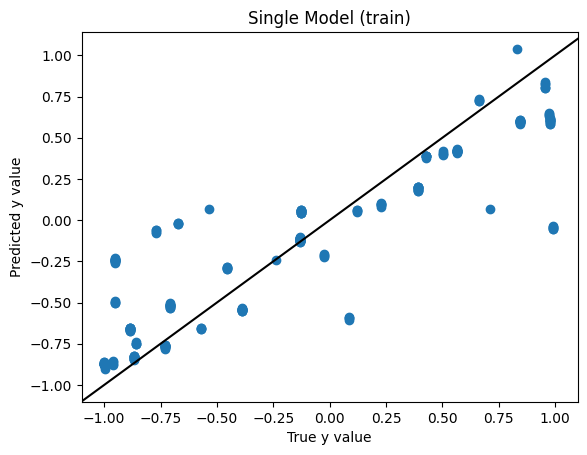

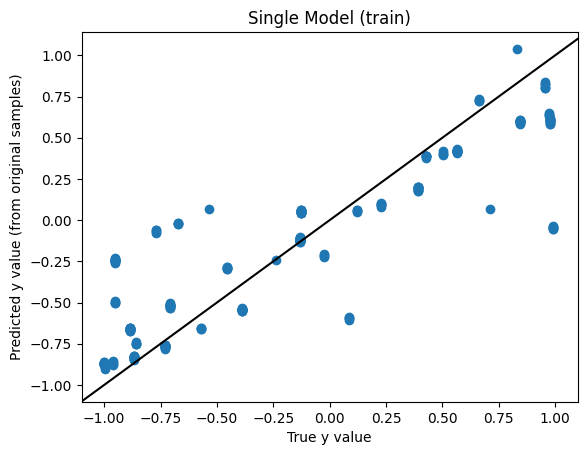

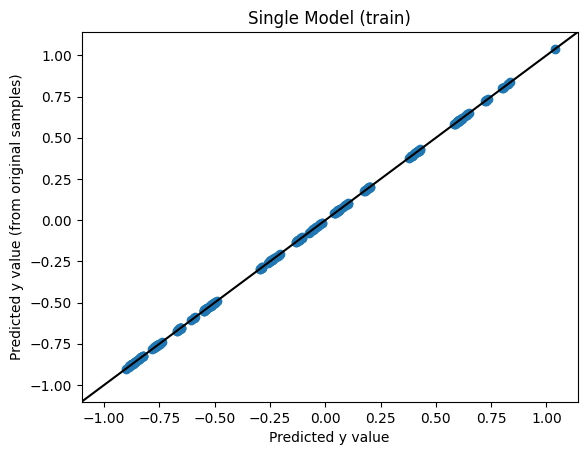

In [9]:
plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

plt.scatter(Y_train_pred_single.mean(dim=0), samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("Predicted y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

#### Next: Layered model

In [10]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_layered = LayeredRegBNN.from_data(X_train_main, Y_train_main, X_train_mm, Y_train_mm, hidden_widths = [256, 256])

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_layered = LayeredRegBNNGuide(model_layered)

In [11]:
adam_layered = pyro.optim.Adam({"lr": learning_rate})
elbo_layered = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi_layered = pyro.infer.SVI(model_layered, guide_layered, adam_layered, elbo_layered)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_layered, losses_layered = do_svi(svi_layered, params = None, min_iter = 10000, X_train_main = X_train_main, Y_train_main = Y_train_main, X_train_aux = X_train_mm, Y_train_aux = Y_train_mm)

2026-09-02 11:16:18 - Start
2026-09-02 11:17:51 - Step 1000, Elbo loss: 164148.9 +/- 32355.6 (slope = -3452.700 +/- 3539.411 loss/k-iter, p-value = 0.026) + 
2026-09-02 11:19:05 - Step 2000, Elbo loss: 161179.6 +/- 31115.7 (slope = -2057.503 +/- 3407.778 loss/k-iter, p-value = 0.114) + *
2026-09-02 11:20:20 - Step 3000, Elbo loss: 156787.4 +/- 21250.7 (slope = -5166.977 +/- 2305.973 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:21:41 - Step 4000, Elbo loss: 154574.0 +/- 25715.7 (slope = -4467.767 +/- 2804.193 loss/k-iter, p-value = 0.001) + 
2026-09-02 11:23:04 - Step 5000, Elbo loss: 150159.6 +/- 21137.6 (slope = -3320.123 +/- 2307.113 loss/k-iter, p-value = 0.002) + 
2026-09-02 11:24:18 - Step 6000, Elbo loss: 145408.5 +/- 16263.6 (slope = -5570.989 +/- 1747.243 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:25:44 - Step 7000, Elbo loss: 140291.6 +/- 15449.4 (slope = -6157.164 +/- 1647.761 loss/k-iter, p-value = 0.000) + 
2026-09-02 11:26:58 - Step 8000, Elbo loss: 132887.5 +/- 1155

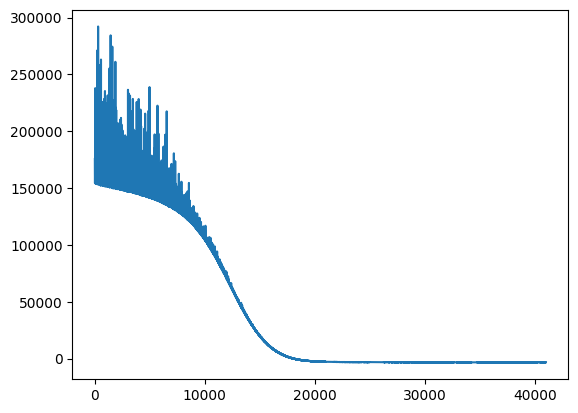

In [12]:
plt.plot(losses_layered)

In [13]:
samples_layered = posterior_samples(guide_layered, params_layered, 1000, X_train_main = X_train_main, Y_train_main = Y_train_main, X_train_aux=X_train_mm, Y_train_aux=Y_train_mm)

In [14]:
pred_layered = predictor(model_layered, samples_layered)
Y_test_pred_layered = pred_layered(X_test)
Y_train_pred_layered = pred_layered(X_train_main)

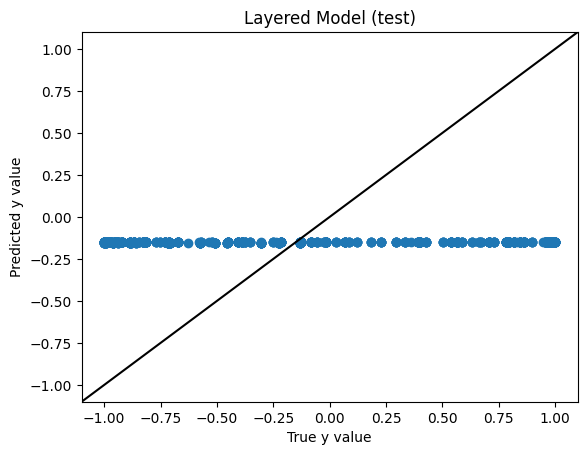

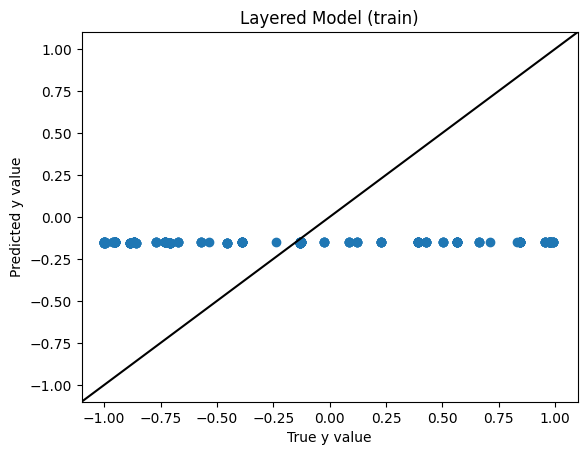

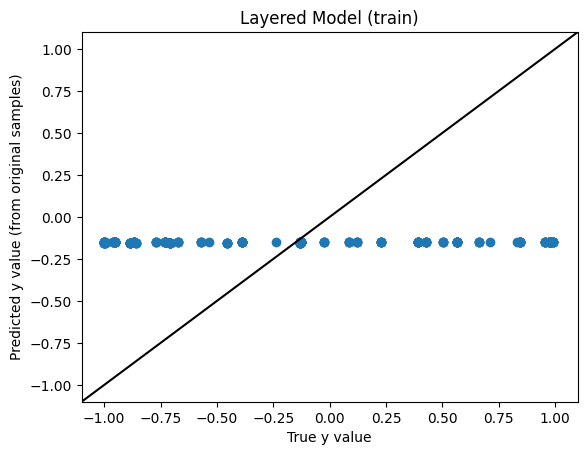

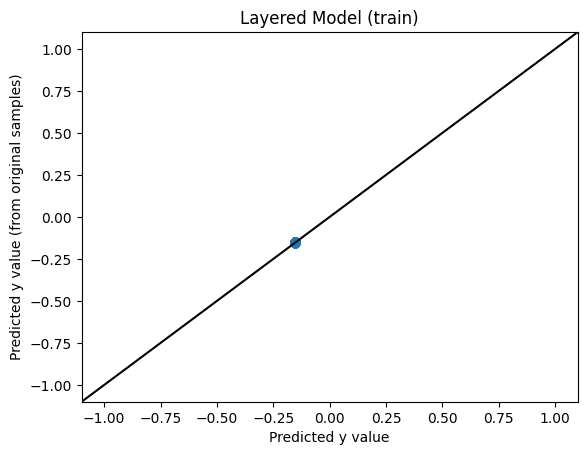

In [15]:
plt.scatter(Y_test_main, Y_test_pred_layered.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Layered Model (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, Y_train_pred_layered.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Layered Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, samples_layered["train_main/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Layered Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

plt.scatter(Y_train_pred_layered.mean(dim=0), samples_layered["train_main/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Layered Model (train)")
plt.xlabel("Predicted y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

### Results so far:

1. I've recreated the initially observed error condition: the layered model predicts a constant mean value while the single model predicts as expected.
2. The layered model does the same thing on both X_train_main and X_test.
3. The training data has the same behavior when using the "train_main/mu" posterior samples instead of the outputs of the predictor function.
    1. The single model still predicts as expected when using the "train/mu" posterior samples. In fact, the mean predictions of both models are nearly identical between the two methods for the training data.
4. Therefore, whatever the problem is, it occurs prior to or during the generation of posterior samples, not while conditioning the network on those samples and predicting.
    1. This doesn't rule out a learning rate issue. The model could just be learning a mean prediction mode. To do: lower the learning rate for the layered model and see what happens. Initial learning rate = 0.001. Resetting (both models, for control) to lr = 0.0001 and running again.
    2. This could also be a caching issue still, but that would be more difficult to track down.
5. Reducing the learning rate by a factor of 10 (item 4.1) did not help. Single model performance and Layered model performance the same.


### Test: how does the layered model do on auxiliary modalities?

I can use the `train_aux/mu` sample sites against `Y_train_mm` to see whether the problem is in auxiliary network as well as main network.

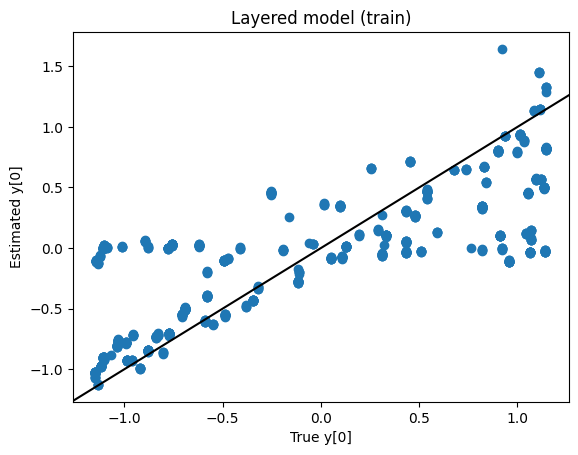

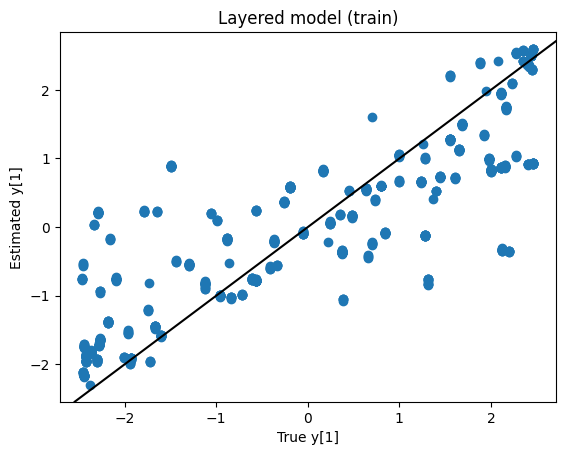

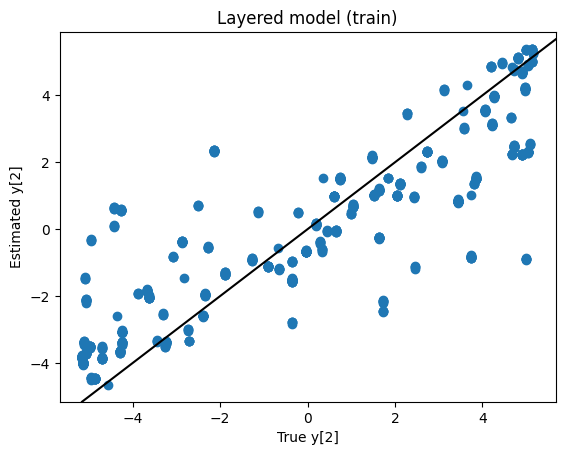

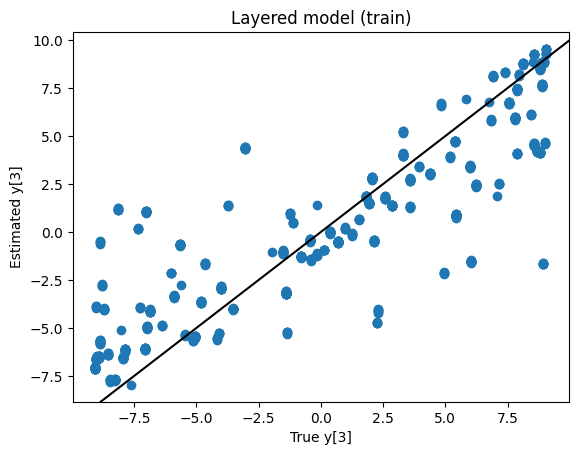

In [21]:
for auxidx in range(4):
    plt.scatter(Y_train_mm[0][:,auxidx], samples_layered["train_aux0/mu"].mean(dim=0)[:,auxidx])
    plt.axline([-1,-1],[1,1], c="black")
    plt.title("Layered model (train)")
    plt.xlabel(f"True y[{auxidx}]")
    plt.ylabel(f"Estimated y[{auxidx}]")
    plt.show()

### Results of previous test:

The layered model is indeed predicting actual values for the auxiliary values, not constant means. Indicating that whatever error is occurring is happening on the main modality only.
1. Is the main network just not conditioning on the observations for some reason?
2. Is the feed-through of X_train_main through the auxiliary network not producing good data for some reason?

In [53]:
# Find the y values of aux data for the X_train_main input values
import torch

def match_rows(X: torch.Tensor, Y: torch.Tensor):
    assert X.ndim == 2
    assert Y.ndim == 2
    assert X.shape[-1] == Y.shape[-1]
    return torch.isclose(X.unsqueeze(1), Y.unsqueeze(0)).all(dim=-1)

matches = match_rows(X_train_main, X_train_mm[0])
pairs = matches.nonzero()
indices = pairs[pairs[:,0].sort().indices,1]
Y_maintrain_mm = Y_train_mm[0][indices,:] # This is the y value for mm data corresponding to X_train_main

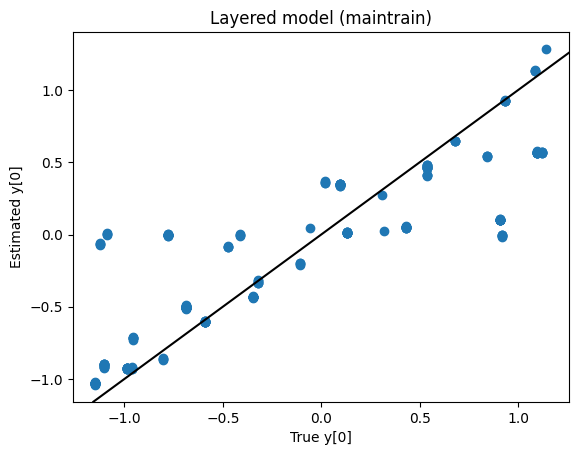

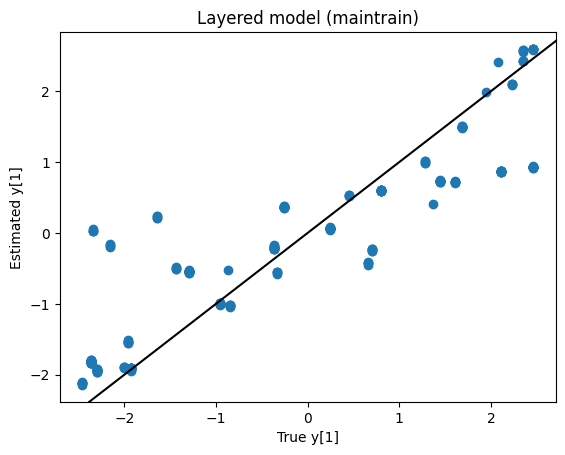

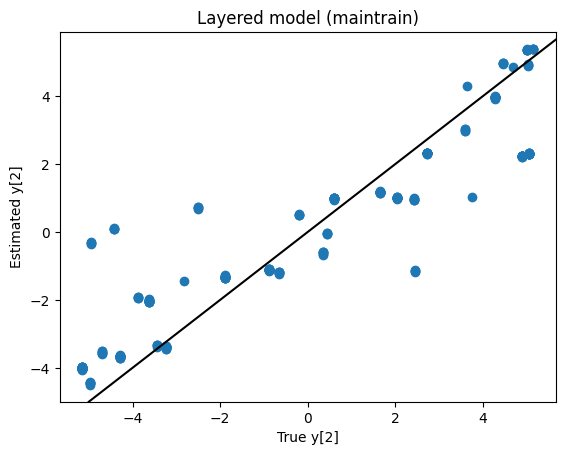

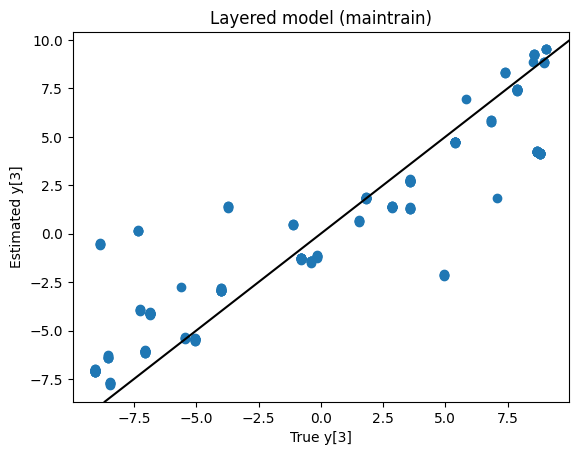

In [54]:
for auxidx in range(4):
    plt.scatter(Y_maintrain_mm[:,auxidx], samples_layered["maintrain_aux0/mu"].mean(dim=0)[:,auxidx])
    plt.axline([-1,-1],[1,1], c="black")
    plt.title("Layered model (maintrain)")
    plt.xlabel(f"True y[{auxidx}]")
    plt.ylabel(f"Estimated y[{auxidx}]")
    plt.show()

The points fed through the auxiliary network to pass on to the main network (for `X_train_main`) look like they should. So the problem is in the main network somehow.